# SAE "Analyse automatique de données" -- Notebook 1 : préparation des données

Dans ce notebook, vous devez :
1. Construire un dataframe avec les données brutes, contenant au moins une colonne pour l'avis textuel et une colonne pour la note correspondante ;
2. Nettoyer les données de ce dataframe (pour supprimer les éventuelles lignes en doublon, traiter les valeurs manquantes...) ;
3. Séparer le dataframe en 3 dataframes : un dataframe pour l'apprentissage, un dataframe pour la validation et un dataframe pour le test ;
4. Sauvegarder chacun des 3 dataframes dans un fichier.


## Modules python utilisés

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
import html
import re


## 1. Construction du dataframe avec les données brutes

In [2]:
# Le fichier a été téléchargé sur https://huggingface.co/datasets/debojit01/fake-review-dataset/tree/main
fake_review_df = pd.read_csv("data/fake_reviews.csv")

# Affichage des headers
fake_review_df.columns.values.tolist()


['category', 'rating', 'label', 'text_']

## 2. Nettoyage des données

In [3]:
# Valeurs nulles
fake_review_df.dropna()


# CG = 0 et OR = 1
fake_review_df.loc[fake_review_df["label"] ==  "CG", "label"] = 0
fake_review_df.loc[fake_review_df["label"] ==  "OR", "label"] = 1

# Détection et suppression du HTML
def clean_html(text):
    if not isinstance(text, str):
        text = str(text)
    
    text = html.unescape(text)
    clean_re = re.compile('<.*?>')
    text = re.sub(clean_re, ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text;

fake_review_df['text_'] = fake_review_df['text_'].apply(clean_html)

# Assure que la colonne est de type int
fake_review_df['label'] = fake_review_df['label'].astype(int)

"""
Nous avons choisi comme règle: 
- rating >= 3 alors positif sinon négatif

Pour équilibrer le dataframe il est nécessaire d'enlever 24616 lignes, car ce dernier est composé à 80% d'avis positif

5.0    24559
4.0     7965
3.0     3786
1.0     2155
2.0     1967
- Somme des avis négatifs = 7908
- Somme des avis positifs = 32524
- Nous allons garder 50 % de note à 5 et 4 soit 3954 par note.

"""
print(f"Avant équilibrage: {fake_review_df['rating'].value_counts()}")

# Suppression des données 5.0 en trop
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 5.0].sample(n=20605).index,inplace=True)
# Suppression des données 4.0 en trop
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 4.0].sample(n=4011).index,inplace=True)
print(f"Après équilibrage: {fake_review_df['rating'].value_counts()}")




Avant équilibrage: rating
5.0    24559
4.0     7965
3.0     3786
1.0     2155
2.0     1967
Name: count, dtype: int64
Après équilibrage: rating
5.0    3954
4.0    3954
3.0    3786
1.0    2155
2.0    1967
Name: count, dtype: int64


## 2.1 Visualisation des données

<Axes: title={'center': 'Nombres de mots'}, xlabel='Nombres de mots par avis', ylabel="Nombres d'avis">

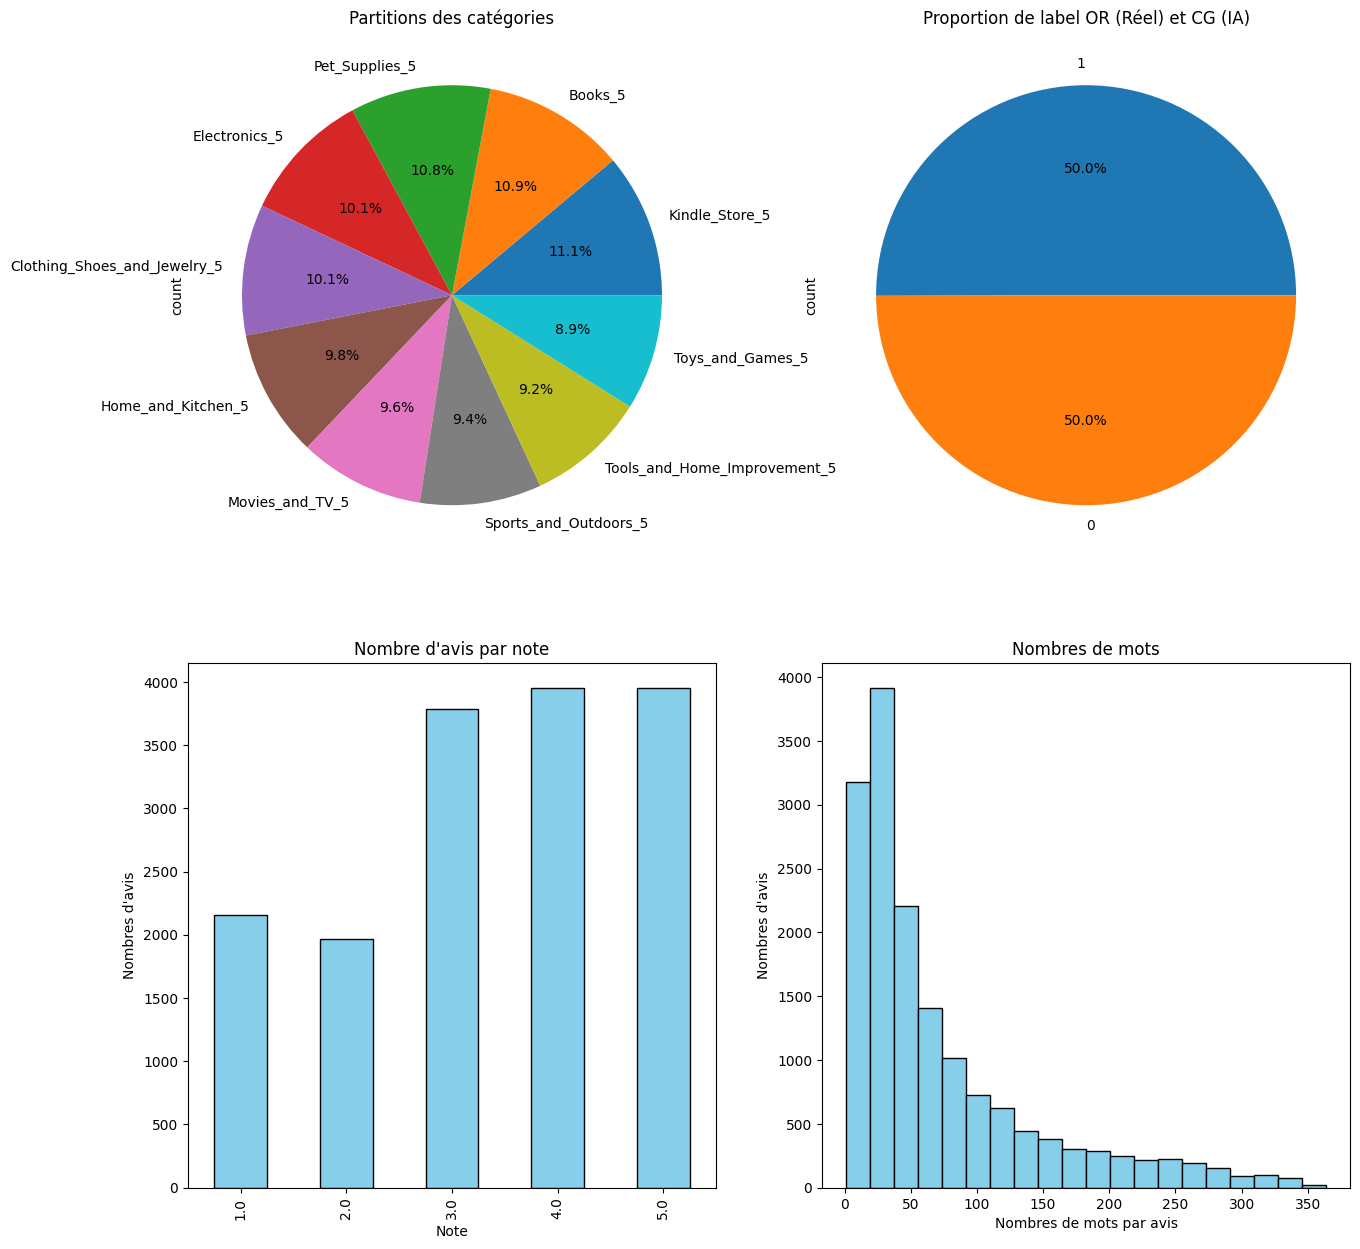

In [4]:
# Visualisation des données d'apprentissage et de tests
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 15))

# Catégories
fake_review_df['category'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0, 0],
    title='Partitions des catégories')

#  Label
fake_review_df['label'].value_counts().plot(kind='pie',
                                            autopct='%1.1f%%',
                                            ax=axes[0, 1],
                                            title='Proportion de label OR (Réel) et CG (IA)')

# Nombre d'avis
fake_review_df['rating'].value_counts().sort_index().plot(kind='bar',
                                                          ax=axes[1, 0],
                                                          color='skyblue',
                                                          edgecolor='black',
                                                          title="Nombre d'avis par note",
                                                          xlabel='Note',
                                                          ylabel="Nombres d'avis")

nb_mots = fake_review_df['text_'].str.split().str.len()
nb_mots.plot(kind='hist',
             bins=20,
             color='skyblue',
             edgecolor='black',
             ax=axes[1, 1],
             title='Nombres de mots',
             xlabel='Nombres de mots par avis',
             ylabel="Nombres d'avis")



## 3. Séparation du dataframe en apprentissage, validation et test

Train: 14234 | Test: 1582
--- Proportions des notes par ensemble ---

Répartition dans Total (Original) (en %) :
rating
1.0    13.63
2.0    12.44
3.0    23.94
4.0    25.00
5.0    25.00
Name: proportion, dtype: float64

Répartition dans Train (en %) :
rating
1.0    13.62
2.0    12.44
3.0    23.94
4.0    25.00
5.0    25.00
Name: proportion, dtype: float64

Répartition dans Test (en %) :
rating
1.0    13.65
2.0    12.45
3.0    23.96
4.0    24.97
5.0    24.97
Name: proportion, dtype: float64
Processeur : passthrough
              precision    recall  f1-score   support

         1.0       0.23      0.19      0.21       216
         2.0       0.13      0.11      0.12       197
         3.0       0.28      0.30      0.29       379
         4.0       0.27      0.26      0.26       395
         5.0       0.36      0.43      0.39       395

    accuracy                           0.28      1582
   macro avg       0.26      0.26      0.25      1582
weighted avg       0.27      0.28      0.28     

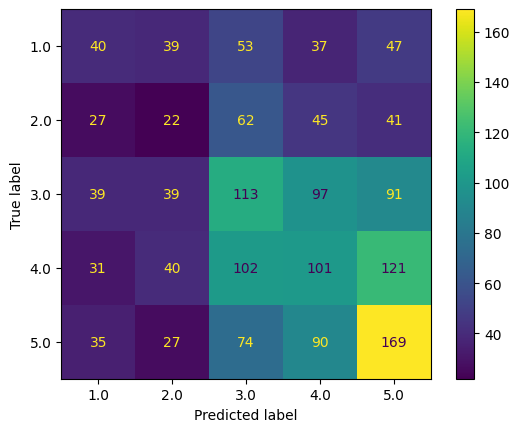

In [5]:
X = fake_review_df[['category', 'text_','label']]
y = fake_review_df['rating']

# On isole l'ensemble de train et de validation de l'ensemble de test
x_train, x_test, y_train, y_test = train_test_split(X, y,
                                                    stratify=y,
                                                    # Distribue les données de manière stratifiée = garantit que chaque sous ensemble à la même proportion de rating
                                                    test_size=0.1,
                                                    random_state=42)


print(f"Train: {len(x_train)} | Test: {len(x_test)}")

# Affichage des différentes métriques
datasets = {
    "Total (Original)": y,
    "Train": y_train,
    "Test": y_test
}

print("--- Proportions des notes par ensemble ---")
for name, data in datasets.items():
    proportions = data.value_counts(normalize=True).sort_index() * 100
    
    print(f"\nRépartition dans {name} (en %) :")
    print(proportions.round(2))

# On défini les différentes transformeurs 
processeur = ColumnTransformer(
    remainder='passthrough',
    transformers=[
        ('review', TfidfVectorizer(), 'text_'),
        ('category', OneHotEncoder(), ['category']),
        ('label', OneHotEncoder(), ['label'])
    ]
)

print(f"Processeur : {processeur.remainder}")

# Mix des transformeurs et du classifieur
model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

model.fit(x_train, y_train)

# Predictions
predictions = model.predict(x_test)
print(classification_report(y_test, predictions))

disp = ConfusionMatrixDisplay(confusion_matrix(y_test, predictions), display_labels=model.classes_)
disp.plot()
plt.show()


## 4. Sauvegarde des dataframes dans des fichiers

In [6]:
def saveDataFrameToCsv(df: pd.DataFrame, filename: str, path: str):
    # Vérifier que le dossier existe
    os.makedirs(path, exist_ok=True)
    completePath = f"{path}/{filename}"
    try:
        df.to_csv(completePath)
        print(f"Dataframe sauvegardé à {completePath}")
    except Exception as e:
        print(f"Dataframe: Erreur de sauvegarde du fichier {filename} dans le dossier {path}, erreur: {e}")


# Sauvegarde du dataframe filtrée
saveDataFrameToCsv(X, "x.csv", "data/df_filtre")
saveDataFrameToCsv(y, "y.csv", "data/df_filtre")

# Sauvegarde des données d'entrainements
saveDataFrameToCsv(x_train, "x_train.csv", "data/train_test")
saveDataFrameToCsv(x_test, "x_test.csv", "data/train_test")
saveDataFrameToCsv(y_train, "y_train.csv", "data/train_test")
saveDataFrameToCsv(y_test, "y_test.csv", "data/train_test")

# Sauvegarde prédiction
saveDataFrameToCsv(pd.DataFrame(predictions), "prediction.csv","data/prediction")

Dataframe sauvegardé à data/df_filtre/x.csv
Dataframe sauvegardé à data/df_filtre/y.csv
Dataframe sauvegardé à data/train_test/x_train.csv
Dataframe sauvegardé à data/train_test/x_test.csv
Dataframe sauvegardé à data/train_test/y_train.csv
Dataframe sauvegardé à data/train_test/y_test.csv
Dataframe sauvegardé à data/prediction/prediction.csv
